# Analysis
## 07 - Partielle Ableitungen: Steigungen in höheren Dimensionen

Partielle Ableitungen $\frac{\partial f}{\partial x}, \frac{\partial f}{\partial y}$ für Funktionen $f(x, y)$ und der Gradient $\nabla f = \begin{pmatrix}\frac{\partial f}{\partial x}\\\frac{\partial f}{\partial y}\end{pmatrix}$ als Vektor der steilsten Steigung und Grundlage des Gradientenabstiegs.

> Vorausgesetzt: Ableitungsregeln.

### Lernziele

- **Partielle Ableitungen** numerisch und symbolisch berechnen
- **Den Gradienten** $\nabla f$ als Vektor der steilsten Steigung
- **3D-Flächen** und **Gradientenfelder** visuell interpretieren
- Zusammenhänge zum Gradientenabstieg (Gradient Descent) erkennen

---

### 1. Definition und numerische Berechnung

Die Definition ist sehr ähnlich zur gewöhnlichen Ableitung. Für die partielle Ableitung nach $x$ ändert sich nur $x$, während $y$ festgehalten wird:
$$
\frac{\partial f}{\partial x}(x, y) = \lim_{h \to 0} \frac{f(x+h, y) - f(x, y)}{h}
$$

Und für $y$:
$$
\frac{\partial f}{\partial y}(x, y) = \lim_{h \to 0} \frac{f(x, y+h) - f(x, y)}{h}
$$

**Praktische Berechnung:** Alle *anderen* Variablen werden wie Konstanten behandelt, und es wird nach den üblichen Ableitungsregeln vorgegangen.

**Beispiel:** $f(x, y) = x^2 y + 2x + y^3$
- $\frac{\partial f}{\partial x} = 2xy + 2$ ($y$ und $y^3$ werden wie Konstanten behandelt)
- $\frac{\partial f}{\partial y} = x^2 + 3y^2$ ($x^2$ und $2x$ werden wie Konstanten behandelt)

Wir können unsere `numerische_ableitung`-Funktion wiederverwenden, indem wir mit Pythons `lambda` temporäre Ein-Variablen-Funktionen erstellen:

In [ ]:
# Eine Funktion mit zwei Variablen
def f_xy(x, y):
    return x**2 * y + 2*x + y**3

# Numerische Ableitung (aus Abschnitt 02)
def numerische_ableitung(f, x, h=1e-7):
    return (f(x + h) - f(x)) / h

# Punkt, an dem wir die partiellen Ableitungen berechnen
x_val, y_val = 3, 4

# --- Partielle Ableitung nach x ---
# y als Konstante behandeln (y_val = 4 einfrieren)
f_nach_x = lambda x: f_xy(x, y_val)
part_x = numerische_ableitung(f_nach_x, x_val)
print(f"Partielle Ableitung ∂f/∂x bei ({x_val}, {y_val}): {part_x:.8f}")
print(f"Exakt: 2xy + 2 = {2*x_val*y_val + 2}")

# --- Partielle Ableitung nach y ---
# x als Konstante behandeln (x_val = 3 einfrieren)
f_nach_y = lambda y: f_xy(x_val, y)
part_y = numerische_ableitung(f_nach_y, y_val)
print(f"\nPartielle Ableitung ∂f/∂y bei ({x_val}, {y_val}): {part_y:.8f}")
print(f"Exakt: x² + 3y² = {x_val**2 + 3*y_val**2}")

Partielle Ableitung ∂f/∂x bei (3, 4): 26.00000045
Exakt: 2xy + 2 = 26

Partielle Ableitung ∂f/∂y bei (3, 4): 57.00000131
Exakt: x² + 3y² = 57


### 2. Der Gradient: Die Richtung des steilsten Anstiegs

Wir haben die Steigung in x-Richtung ($\frac{\partial f}{\partial x}$) und die Steigung in y-Richtung ($\frac{\partial f}{\partial y}$) berechnet. Was passiert, wenn wir diese beiden Werte zu einem **Vektor** zusammenfassen?

Diesen Vektor nennt man den **Gradienten**, geschrieben als $\nabla f$ (gesprochen: „Nabla f"):

$$
\nabla f(x, y) = \begin{pmatrix} \frac{\partial f}{\partial x} \\ \frac{\partial f}{\partial y} \end{pmatrix}
$$

Der Gradient hat zwei wichtige Eigenschaften:
1. **Richtung:** Der Gradientvektor zeigt immer in die Richtung des **steilsten Anstiegs**. Wenn Du auf einem Berg stehst und so schnell wie möglich nach oben willst, gehst Du in Richtung des Gradienten.
2. **Betrag:** Die Länge (der Betrag) des Gradientvektors gibt an, **wie steil** dieser Anstieg ist. Längerer Vektor = steilerer Anstieg.

Der **negative Gradient** ($-\nabla f$) zeigt in die Richtung des **steilsten Abstiegs** - das ist die Kernidee hinter dem **Gradientenabstieg** (Gradient Descent), einem der wichtigsten Algorithmen im maschinellen Lernen.

---

### 3. 3D-Visualisierung: Die Funktionslandschaft

Zuerst visualisieren wir die Funktion $f(x, y)$ als 3D-Fläche. Das zeigt die tatsächliche „Landschaft" der Funktion:

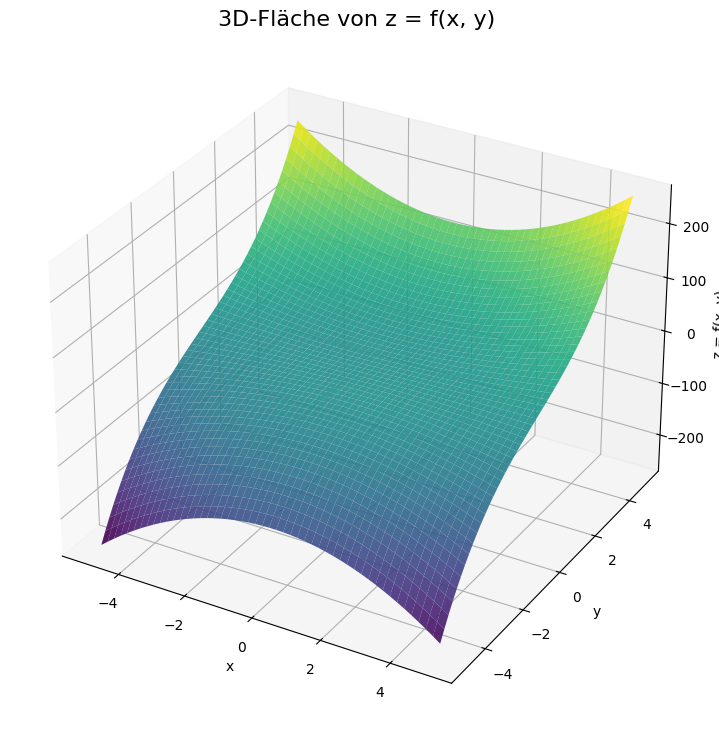

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def f_xy(x, y):
    return x**2 * y + 2*x + y**3

# --- 3D-Flächenplot ---
Flaeche_3D_Config = {
    "bereich": (-5, 5),
    "punkte": 50,
    "figsize": (10, 9),
    "blickwinkel": (30, -60),
}

def visualisiere_3d_flaeche(config):
    """Zeichnet die Funktion f(x,y) als 3D-Fläche."""
    x_vals = np.linspace(*config["bereich"][:2], config["punkte"])
    y_vals = np.linspace(*config["bereich"][:2], config["punkte"])
    X, Y = np.meshgrid(x_vals, y_vals)
    Z = f_xy(X, Y)

    fig = plt.figure(figsize=config["figsize"])
    ax = fig.add_subplot(111, projection='3d')

    ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.9)

    ax.set_title('3D-Fläche von z = f(x, y)', fontsize=16)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z = f(x, y)')
    ax.view_init(elev=config["blickwinkel"][0], azim=config["blickwinkel"][1])
    plt.show()

visualisiere_3d_flaeche(Flaeche_3D_Config)

### 4. 2D-Darstellung: Gradientenfeld als Heatmap

Jetzt visualisieren wir das Ganze von oben: Eine 2D-Heatmap zeigt den Wert von $f(x,y)$ durch Farbe, und darüber legen wir **Pfeile** (ein „Quiver-Plot"), die die Gradientvektoren an verschiedenen Stellen darstellen.

- Pfeile zeigen **bergauf** - von dunklen (niedrigen) zu hellen (hohen) Regionen
- Gelbe Bereiche = hohe Gipfel, violette Bereiche = tiefe Täler
- Längere Pfeile = steilere Steigung

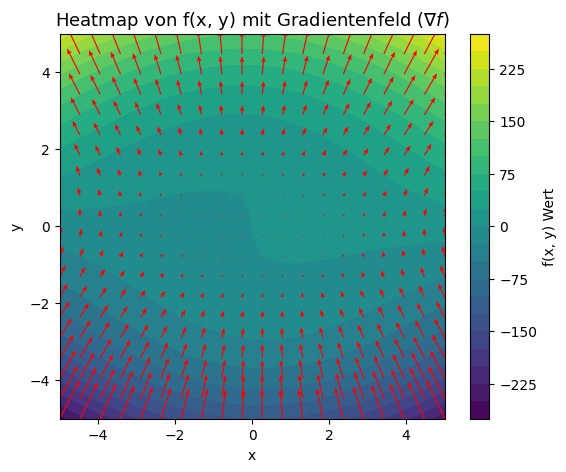


Für f(x, y) = x²y + 2x + y³:
--------------------------------------------------
Punkt (-1, -2):
  f(x,y)  = -12
  ∇f      = (6, 13)
  |∇f|    = 14.32 (Steilheit)

Punkt (-3, 4):
  f(x,y)  = 94
  ∇f      = (-22, 57)
  |∇f|    = 61.10 (Steilheit)

Punkt (3, 1):
  f(x,y)  = 16
  ∇f      = (8, 12)
  |∇f|    = 14.42 (Steilheit)



In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Funktion und Gradient
def f_xy(x, y):
    return x**2 * y + 2*x + y**3

def gradient_f_xy(x, y):
    """Der symbolische Gradient von f(x,y):
    ∂f/∂x = 2xy + 2
    ∂f/∂y = x² + 3y²
    """
    df_dx = 2*x*y + 2
    df_dy = x**2 + 3*y**2
    return np.array([df_dx, df_dy])

# --- Gradientenfeld-Heatmap ---
Gradient_Config = {
    "bereich": (-5, 5),
    "gitterpunkte": 20,
    "kontour_levels": 20,
    "pfeil_skalierung": 1000,
    "figsize": (6.25, 5),
}

def visualisiere_gradientenfeld(config):
    """Zeichnet eine Heatmap mit Gradientpfeilen."""
    x_vals = np.linspace(*config["bereich"][:2], config["gitterpunkte"])
    y_vals = np.linspace(*config["bereich"][:2], config["gitterpunkte"])
    X, Y = np.meshgrid(x_vals, y_vals)
    Z = f_xy(X, Y)

    # Gradient an jedem Gitterpunkt
    U, V = gradient_f_xy(X, Y)

    plt.figure(figsize=config["figsize"])

    # Gefüllter Konturplot (Heatmap)
    contour = plt.contourf(X, Y, Z, levels=config["kontour_levels"], cmap='viridis')
    plt.colorbar(contour, label='f(x, y) Wert')

    # Gradientvektoren (Pfeile)
    plt.quiver(X, Y, U, V, color='red', scale=config["pfeil_skalierung"], headwidth=4)

    plt.title(r'Heatmap von f(x, y) mit Gradientenfeld ($\nabla f$)', fontsize=13)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.axis('scaled')
    plt.show()

visualisiere_gradientenfeld(Gradient_Config)

# --- Stichproben an ausgewählten Punkten ---
punkte = [(-1, -2), (-3, 4), (3, 1)]

print(f"\nFür f(x, y) = x²y + 2x + y³:")
print("-" * 50)
for px, py in punkte:
    f_wert = f_xy(px, py)
    grad = gradient_f_xy(px, py)
    betrag = np.linalg.norm(grad)
    print(f"Punkt ({px}, {py}):")
    print(f"  f(x,y)  = {f_wert}")
    print(f"  ∇f      = ({grad[0]}, {grad[1]})")
    print(f"  |∇f|    = {betrag:.2f} (Steilheit)")
    print()

---

## Verständnis-Check
*Löse die folgenden Aufgaben eigenständig, bevor du die Lösungen konsultierst.*

**Aufgabe 1:** Berechne die partiellen Ableitungen:
- a) $f(x, y) = 3x^2y - 4xy^2 + y$ → $\frac{\partial f}{\partial x}$ und $\frac{\partial f}{\partial y}$
- b) $f(x, y) = x \cdot e^{xy}$ → $\frac{\partial f}{\partial x}$ und $\frac{\partial f}{\partial y}$

**Aufgabe 2:** Berechne den Gradienten $\nabla f$ für $f(x,y) = x^2 + y^2$ an der Stelle $(3, 4)$.
- In welche Richtung zeigt der Gradient?
- Wie groß ist der Betrag $|\nabla f|$?

**Aufgabe 3:** Für $f(x, y) = x^2 + y^2$ zeigt der Gradient immer vom Ursprung weg. Warum ist das so? *(Tipp: Was für eine Fläche ist das?)*

**Aufgabe 4:** In welche Richtung würde ein Gradientenabstiegs-Algorithmus laufen, wenn er bei $(3, 4)$ auf der Fläche $f(x,y) = x^2 + y^2$ startet?

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

a)
- $\frac{\partial f}{\partial x} = 6xy - 4y^2$ ($y$ festhalten, nach $x$ ableiten)
- $\frac{\partial f}{\partial y} = 3x^2 - 8xy + 1$ ($x$ festhalten, nach $y$ ableiten)

b) Hier braucht man die Produktregel!
- $\frac{\partial f}{\partial x} = e^{xy} + x \cdot ye^{xy} = e^{xy}(1 + xy)$ (Produktregel: $u=x, v=e^{xy}$)
- $\frac{\partial f}{\partial y} = x \cdot xe^{xy} = x^2 e^{xy}$ (Kettenregel: innere Abl. von $xy$ nach $y$ ist $x$)
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

$f(x,y) = x^2 + y^2$

- $\frac{\partial f}{\partial x} = 2x$, $\frac{\partial f}{\partial y} = 2y$
- $\nabla f(3, 4) = (6, 8)$
- $|\nabla f| = \sqrt{6^2 + 8^2} = \sqrt{100} = 10$
- Der Gradient zeigt in Richtung $(6, 8)$, also nach rechts-oben.
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

$f(x,y) = x^2 + y^2$ beschreibt ein **Paraboloid** (eine „Schüssel") mit Minimum im Ursprung. Der Gradient $\nabla f = (2x, 2y)$ zeigt immer radial nach außen, weil die steilste Steigung immer *weg* vom Tiefpunkt führt.
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

Der Gradientenabstieg folgt $-\nabla f = -(6, 8) = (-6, -8)$, also in Richtung des Ursprungs - genau zum Minimum der Funktion!
</details>

---

## Zusammenfassung

| Konzept | Kernaussage |
|---------|-------------|
| **Partielle Ableitung** | Steigung in *einer* Richtung, andere Variablen festhalten |
| **Berechnung** | Andere Variablen wie Konstanten behandeln und normal ableiten |
| **Gradient** | $\nabla f$ fasst alle partiellen Ableitungen zu einem Vektor zusammen |
| **Richtung** | $\nabla f$ zeigt zum **steilsten Anstieg**, $-\nabla f$ bergab |
| **3D-Visualisierung** | Funktion als Fläche, Gradient als Pfeilfeld |


---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Partielle Ableitung | Partial derivative |
| Gradient | Gradient |
| Gradientenfeld | Gradient field |
| Steilster Anstieg | Steepest ascent |
| Steilster Abstieg | Steepest descent |
| Gradientenabstieg | Gradient descent |
| Heatmap | Heatmap |
| Höhenlinie / Konturlinie | Contour line |
| Betrag (eines Vektors) | Magnitude (of a vector) |
| Mehrere Variablen | Multiple variables |